In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import os
import sys
import astropy as ast
import matplotlib.pyplot as plt
import pandas as pd
import glob
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.colors import LogNorm, Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
import matplotlib.path as mpath
from pathlib import Path
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import MultipleLocator, AutoMinorLocator, FormatStrFormatter, FuncFormatter
import mesa_reader as mr
fourpointstar = mpath.Path.unit_regular_star(4)
sevenpointstar = mpath.Path.unit_regular_star(7)
eightpointstar = mpath.Path.unit_regular_star(8)
from metrics_newlcs_sept26 import fit_plotter_flux, compute_lomb_scargle, plot_periodogram, info, plot_phase_fold_binned, plot_phase_fold

In [2]:
# sample = pd.read_csv(
#     './ysg_candidates_Tcut_nocontaminants_08272026.csv'
# ).set_index('star_idx', drop=False)

sample = pd.read_csv(
    './summary_results09152026.csv'
).set_index('star_idx', drop=False)

Number of stars in first bin (0-10 days): 10


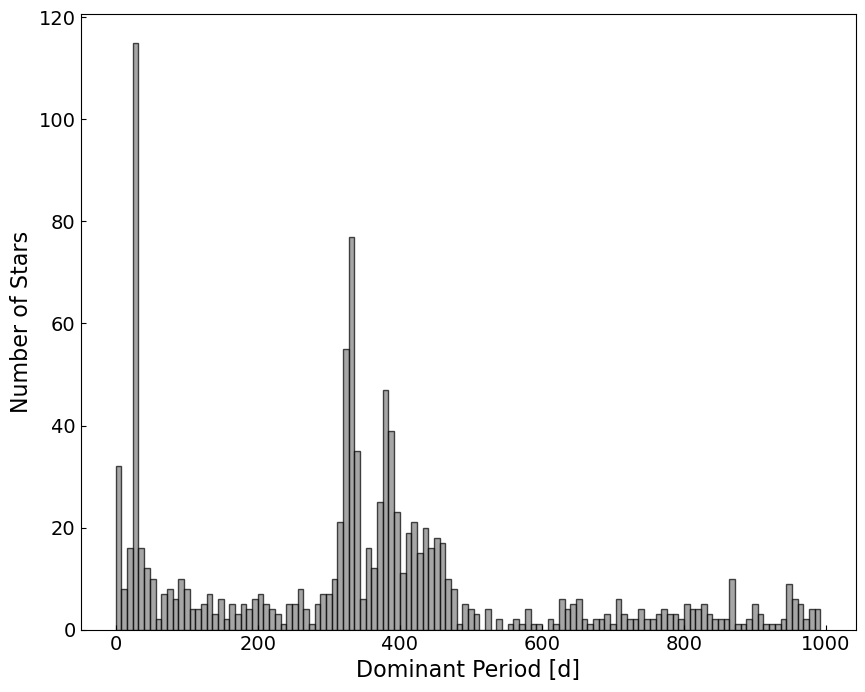

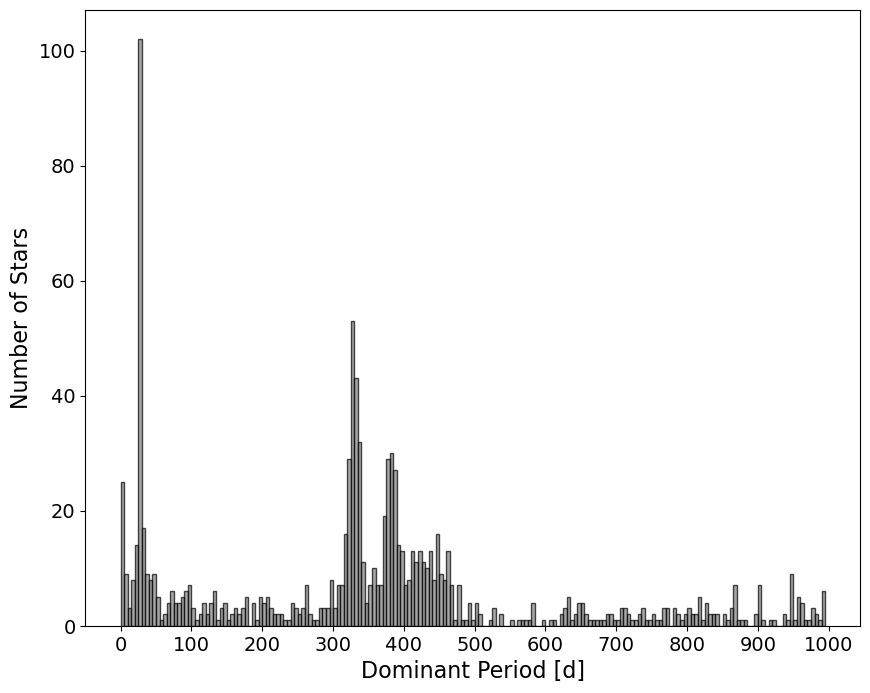

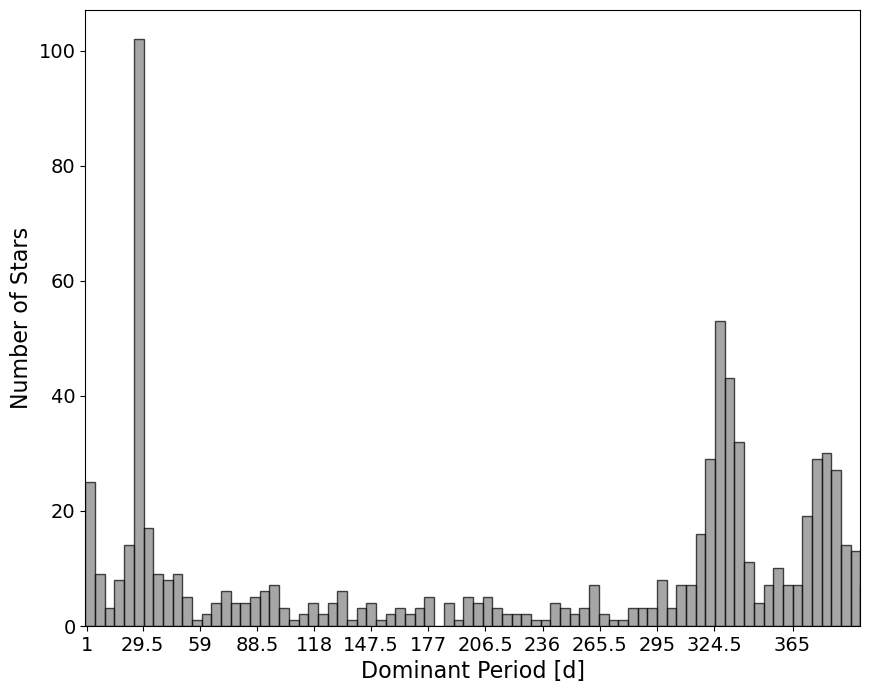

In [3]:
# histogram of periods

fig, ax = plt.subplots(figsize=(10, 8))
ax.hist(sample['best_period'], bins=np.arange(0, 1000, 8), alpha=0.7, color='grey', edgecolor='black')
# print the number ni the first bin
print(f"Number of stars in first bin (0-10 days): {np.sum((sample['best_period'] >= 0) & (sample['best_period'] < 2))}")
ax.set_xlabel("Dominant Period [d]", fontsize=16)
ax.set_ylabel("Number of Stars", fontsize=16)
ax.tick_params(axis="both", direction="in", labelsize=14)
plt.savefig("./figs/period_histogram.png", dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 8))
ax.hist(sample['best_period'], bins=np.arange(0, 1000, 5), alpha=0.7, color='grey', edgecolor='black')
ax.set_xlabel("Dominant Period [d]", fontsize=16)
ax.set_ylabel("Number of Stars", fontsize=16)
ax.tick_params(axis="both", direction="out", labelsize=14)
# ax.set_xlim(0,400)
# diy markers on the x axis
# xticks = [1.0, 29.5, 29.5*2, 29.5*3, 29.5*4, 29.5*5, 29.5*6, 29.5*7, 29.5*8, 29.5*9, 29.5*10, 29.5*11, 365]
# ax.set_xticks(xticks)
# ax.set_xticklabels(['1', '29.5', '59', '88.5', '118', '147.5', '177', '206.5', '236', '265.5', '295', '324.5', '365'])
ax.set_xticks(np.arange(0, 1001, 100))
# plt.savefig("./figs/period_histogram.png", dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 8))
ax.hist(sample['best_period'], bins=np.arange(0, 1000, 5), alpha=0.7, color='grey', edgecolor='black')
ax.set_xlabel("Dominant Period [d]", fontsize=16)
ax.set_ylabel("Number of Stars", fontsize=16)
ax.tick_params(axis="both", direction="out", labelsize=14)
ax.set_xlim(0,400)
# diy markers on the x axis
xticks = [1.0, 29.5, 29.5*2, 29.5*3, 29.5*4, 29.5*5, 29.5*6, 29.5*7, 29.5*8, 29.5*9, 29.5*10, 29.5*11, 365]
ax.set_xticks(xticks)
ax.set_xticklabels(['1', '29.5', '59', '88.5', '118', '147.5', '177', '206.5', '236', '265.5', '295', '324.5', '365'])
# ax.set_xticks(np.arange(0, 401, 50))
# plt.savefig("./figs/period_histogram.png", dpi=300, bbox_inches="tight")
plt.show()

In [13]:
# let's pull out targets within a certain period range
lunar_cycle_range = (29.5 - 2, 29.5 + 2)
sample_lunar = sample[(sample['best_period'] >= lunar_cycle_range[0]) & (sample['best_period'] <= lunar_cycle_range[1])]
print(f"Number of stars with periods within {lunar_cycle_range[0]} and {lunar_cycle_range[1]} days: {len(sample_lunar)}")
print(sample_lunar[['star_idx', 'best_period']])



other_alias_range = (328 - 5, 328 + 5)
other_alias = sample[(sample['best_period'] >= other_alias_range[0]) & (sample['best_period'] <= other_alias_range[1])]
print(f"Number of stars with periods within {other_alias_range[0]} and {other_alias_range[1]} days: {len(other_alias)}")
print(other_alias[['star_idx', 'best_period']])

Number of stars with periods within 27.5 and 31.5 days: 97
          star_idx  best_period
star_idx                       
19              19    28.437143
23              23    29.513746
30              30    29.542559
46              46    29.542761
62              62    29.499131
...            ...          ...
1022          1022    29.553882
1076          1076    29.560442
1141          1141    29.556775
1173          1173    29.598169
1242          1242    29.520398

[97 rows x 2 columns]
Number of stars with periods within 323 and 333 days: 95
          star_idx  best_period
star_idx                       
9                9   331.630545
52              52   329.215469
58              58   332.291984
69              69   332.688519
71              71   331.762888
...            ...          ...
1208          1208   332.712211
1226          1226   327.041435
1237          1237   332.420523
1263          1263   327.450615
1264          1264   329.140657

[95 rows x 2 columns]


Star index: 9, Best period: 331.6305452259631


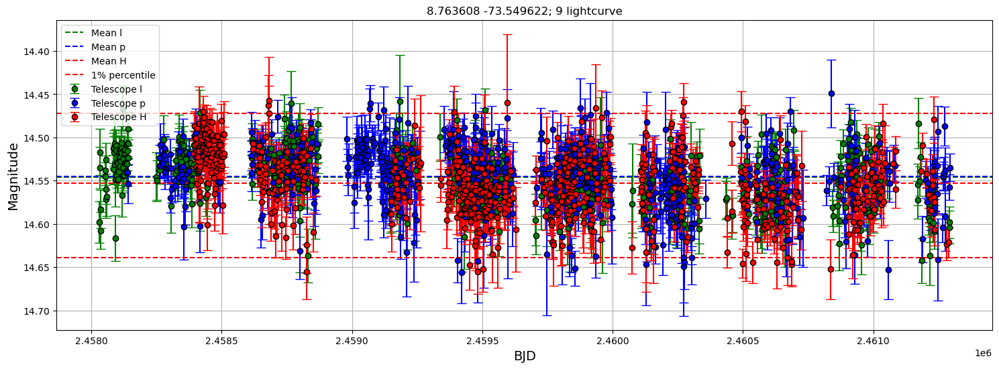

Best frequency: 0.003015 1/day, Best period: 331.63 days, Max power: 0.046, False alarm probability: 1.570e-16
False alarm level for 1.0%: 1.434e-02
Grid sampled at 17969 points


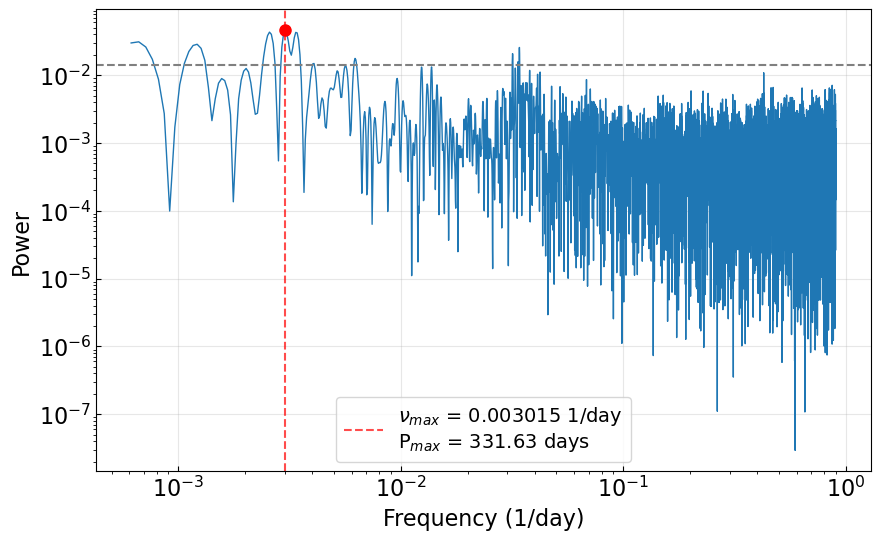

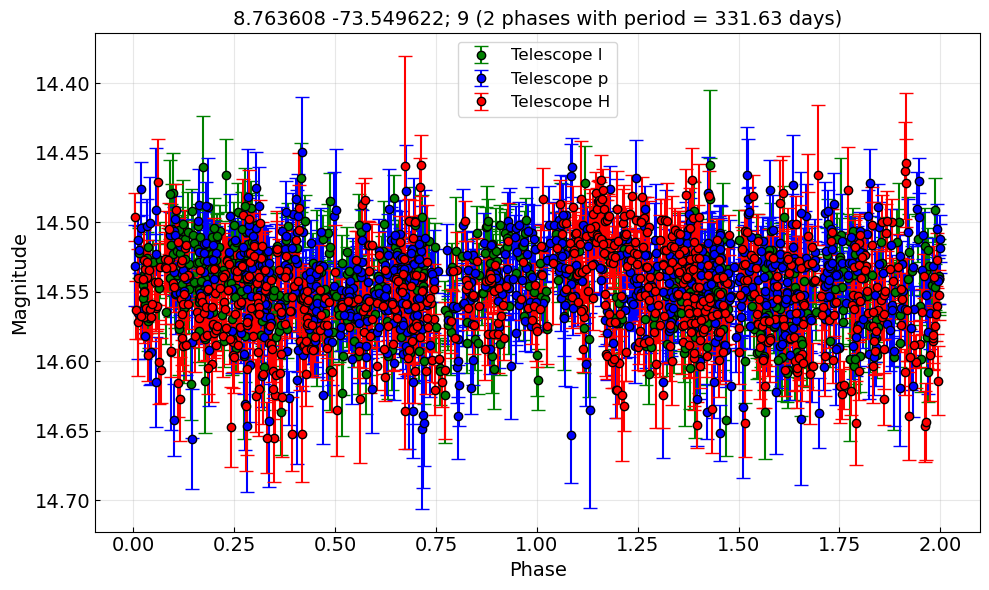

Average scatter (amplitude) per 10 point phase bin: 0.488 mJy


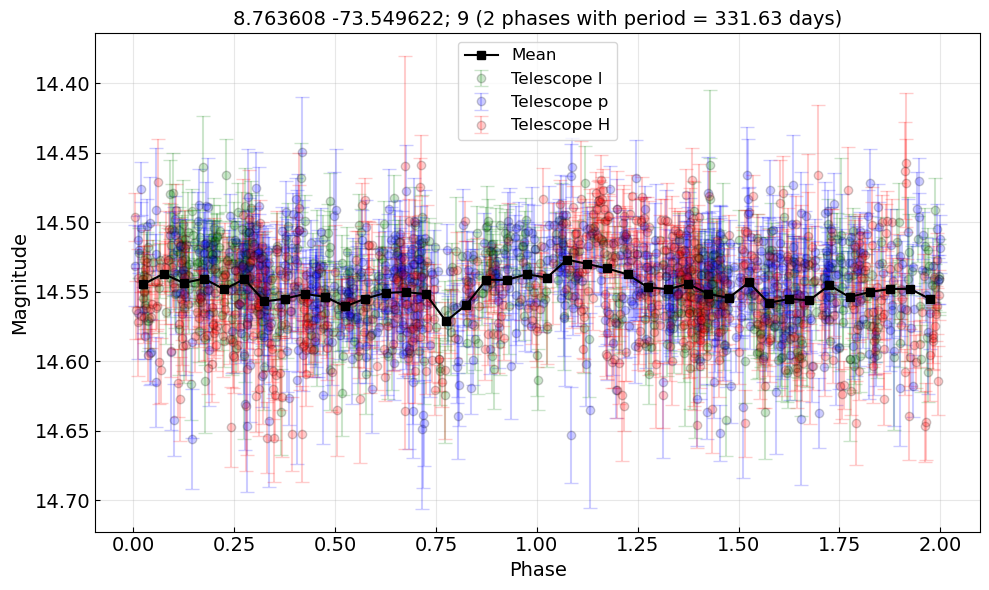

Average scatter (amplitude) per 10 point phase bin: 0.488 mJy
[0.00066282 0.00121343 0.0030154  0.00406656 0.00621892 0.03174694
 0.03404947]
Amplitude metrics:
	Lower 5% percentile: -0.30 mJy, 14.50 mags
	Upper 5% percentile: 0.26 mJy, 14.61 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 0.56 mJy, 0.11 mags
Amplitude metrics:
	Lower 1% percentile: -0.45 mJy, 14.47 mags
	Upper 1% percentile: 0.39 mJy, 14.64 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 0.84 mJy, 0.17 mags
	Largest amplitude of variability (g-band: True): 1.05 mJy, 0.21 mags
	Average amplitude across all periods: 0.916 mJy
	Standard deviation of amplitudes: 0.082 mJy
	Average amplitude (0.916 mJy) is greater than 5 sigma (0.082 mJy). This indicates consistent variability across periods.
Star index: 52, Best period: 329.2154694371997


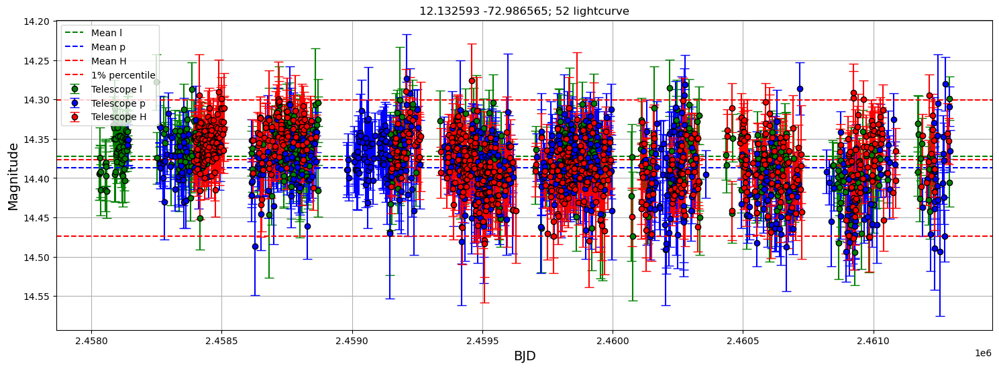

Best frequency: 0.003038 1/day, Best period: 329.22 days, Max power: 0.041, False alarm probability: 1.691e-14
False alarm level for 1.0%: 1.416e-02
Grid sampled at 18176 points


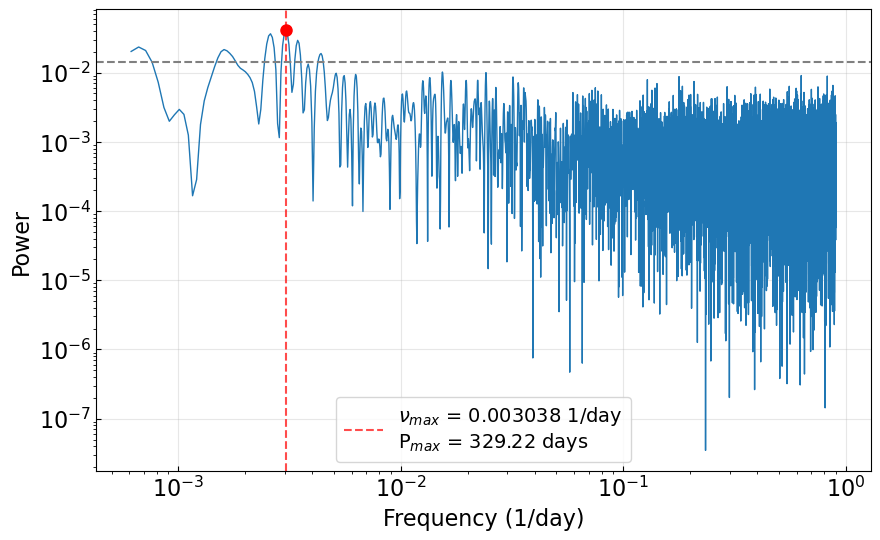

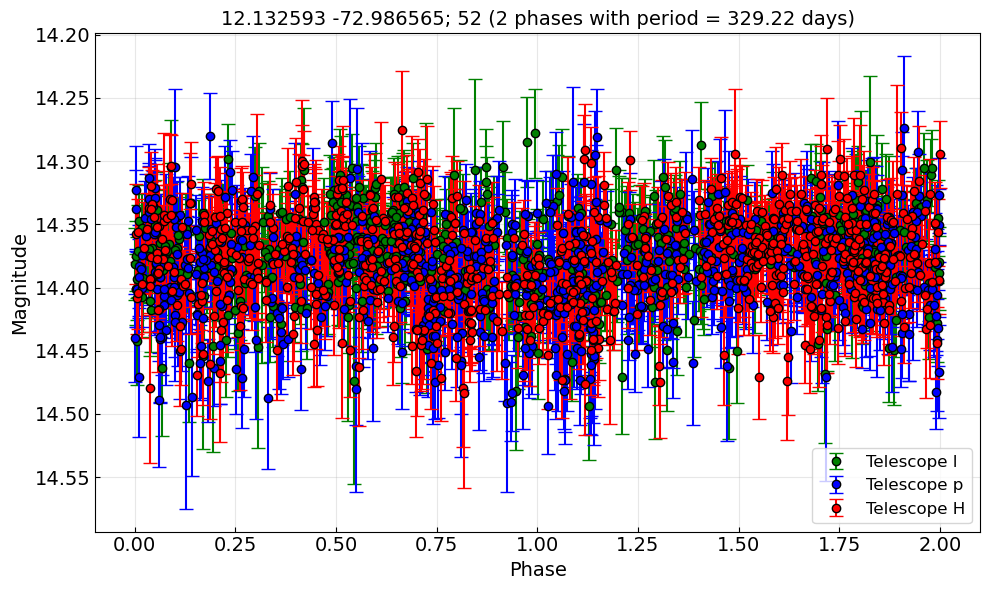

Average scatter (amplitude) per 10 point phase bin: 0.617 mJy


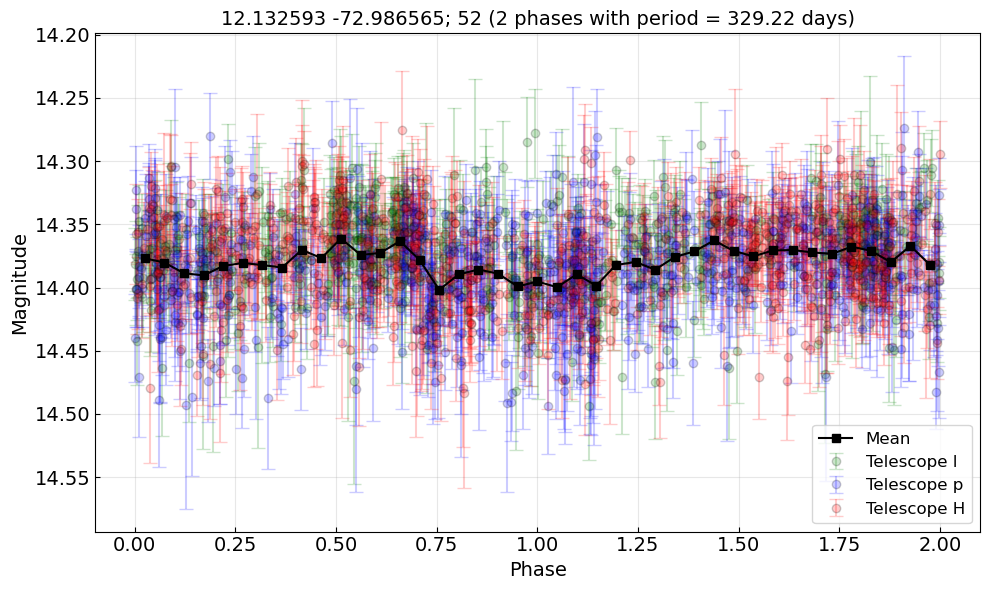

Average scatter (amplitude) per 10 point phase bin: 0.617 mJy
[0.00066225 0.00160246 0.00303752 0.00437362]
Amplitude metrics:
	Lower 5% percentile: -0.40 mJy, 14.32 mags
	Upper 5% percentile: 0.33 mJy, 14.45 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 0.72 mJy, 0.12 mags
Amplitude metrics:
	Lower 1% percentile: -0.55 mJy, 14.30 mags
	Upper 1% percentile: 0.47 mJy, 14.47 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 1.02 mJy, 0.17 mags
	Largest amplitude of variability (g-band: True): 1.30 mJy, 0.22 mags
	Average amplitude across all periods: 1.139 mJy
	Standard deviation of amplitudes: 0.091 mJy
	Average amplitude (1.139 mJy) is greater than 5 sigma (0.091 mJy). This indicates consistent variability across periods.
Star index: 58, Best period: 332.2919837102322


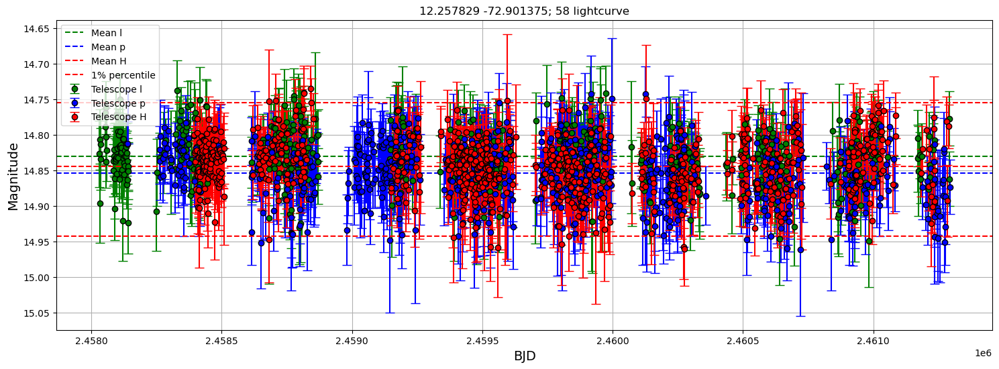

Best frequency: 0.003009 1/day, Best period: 332.29 days, Max power: 0.021, False alarm probability: 1.572e-05
False alarm level for 1.0%: 1.429e-02
Grid sampled at 18014 points


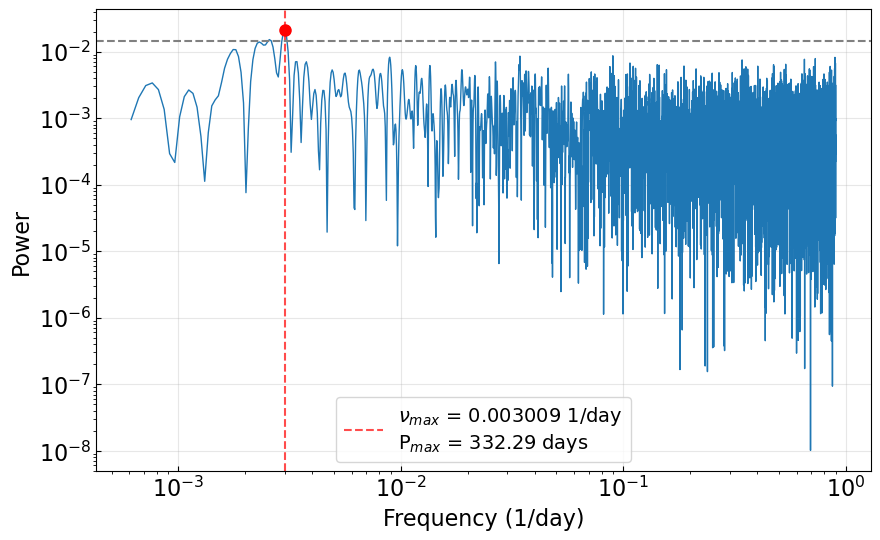

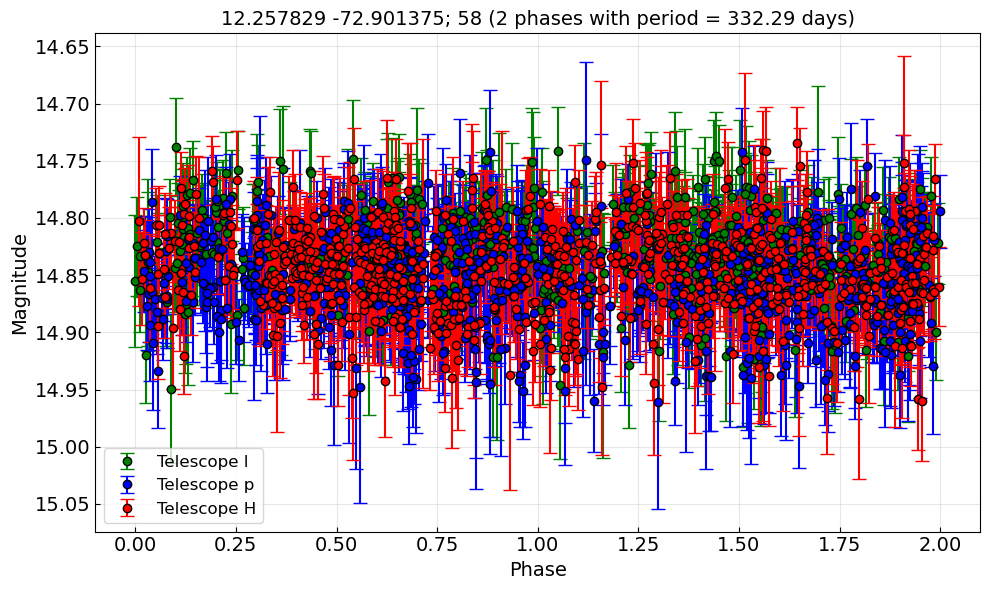

Average scatter (amplitude) per 10 point phase bin: 0.427 mJy


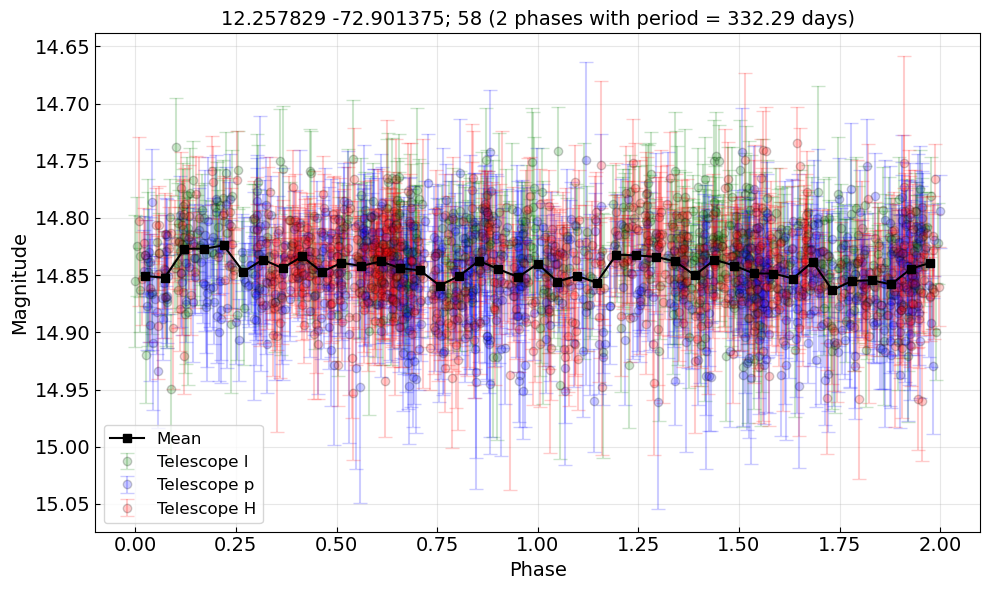

Average scatter (amplitude) per 10 point phase bin: 0.427 mJy
[0.0030094]
Amplitude metrics:
	Lower 5% percentile: -0.27 mJy, 14.78 mags
	Upper 5% percentile: 0.23 mJy, 14.91 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 0.50 mJy, 0.13 mags
Amplitude metrics:
	Lower 1% percentile: -0.37 mJy, 14.75 mags
	Upper 1% percentile: 0.35 mJy, 14.94 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 0.72 mJy, 0.19 mags
	Largest amplitude of variability (g-band: True): 0.87 mJy, 0.23 mags
	Average amplitude across all periods: 0.770 mJy
	Standard deviation of amplitudes: 0.052 mJy
	Average amplitude (0.770 mJy) is greater than 5 sigma (0.052 mJy). This indicates consistent variability across periods.
Star index: 69, Best period: 332.6885187277708


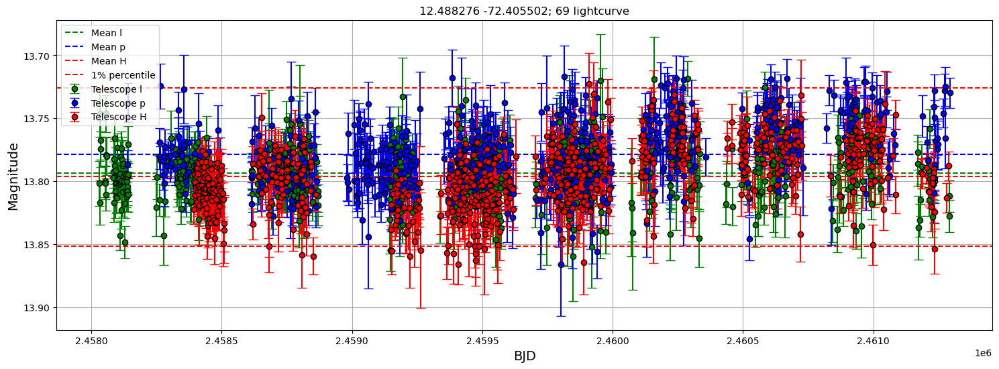

Best frequency: 0.003006 1/day, Best period: 332.69 days, Max power: 0.079, False alarm probability: 1.187e-31
False alarm level for 1.0%: 1.429e-02
Grid sampled at 18041 points


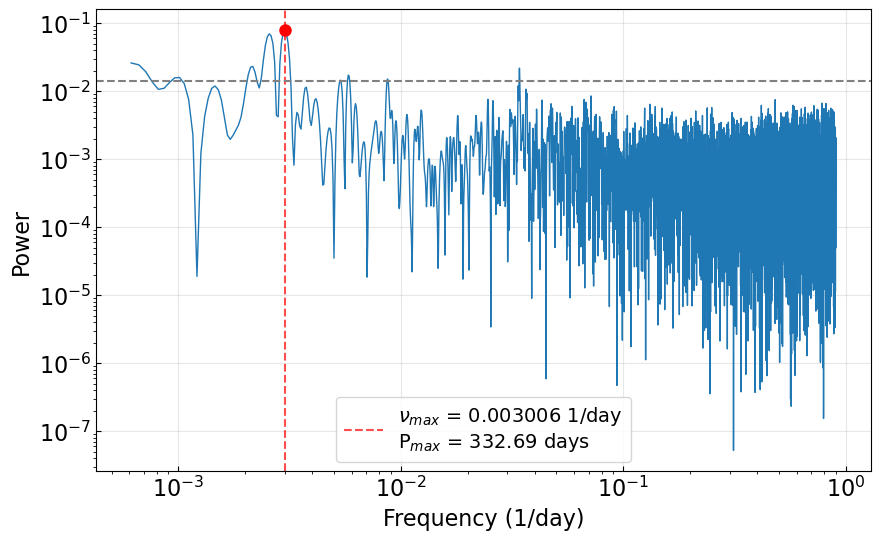

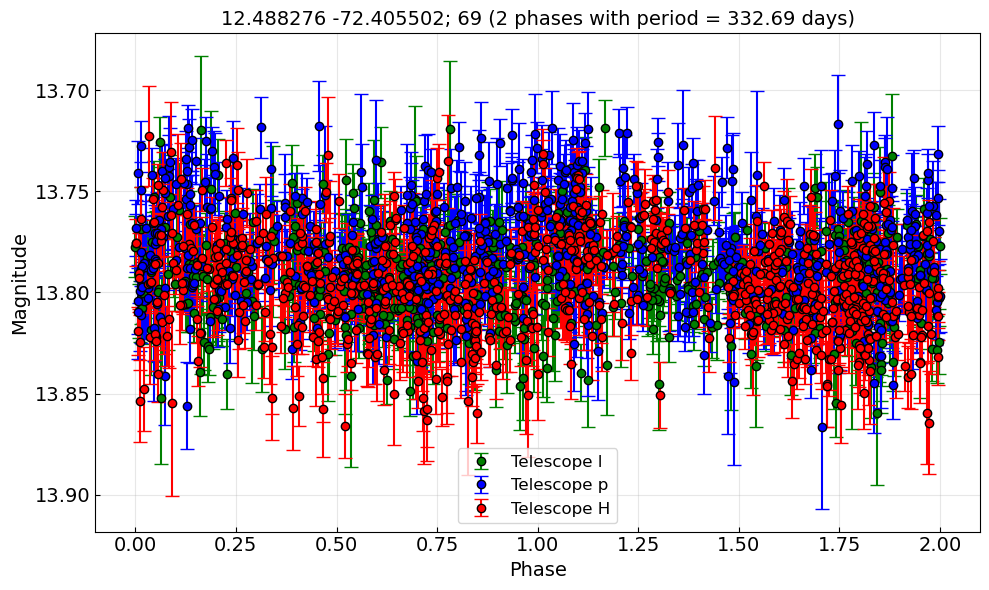

Average scatter (amplitude) per 10 point phase bin: 0.748 mJy


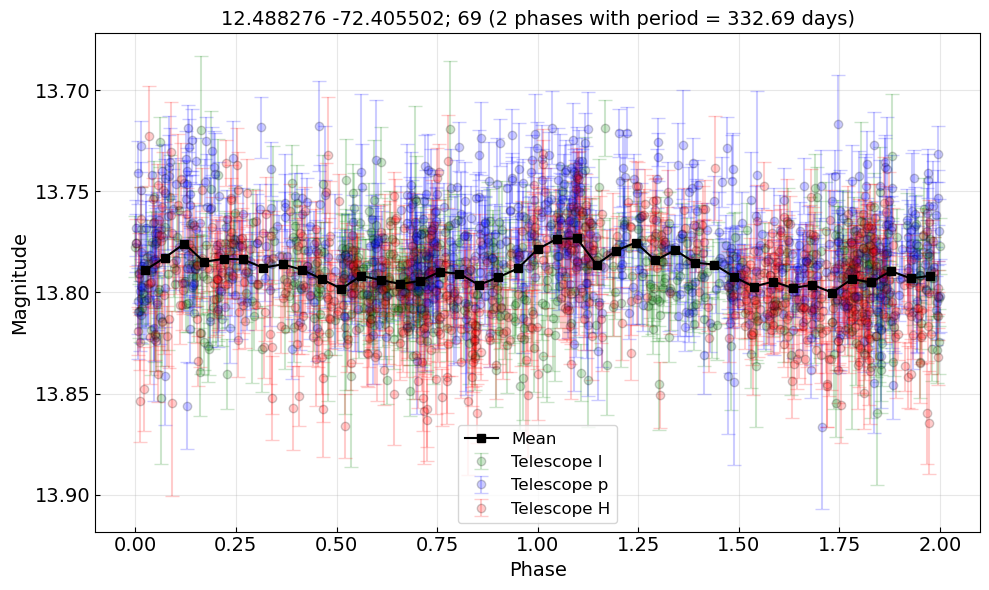

Average scatter (amplitude) per 10 point phase bin: 0.748 mJy
[0.00101161 0.00215828 0.00300581 0.0057977  0.0086893  0.03406558]
Amplitude metrics:
	Lower 5% percentile: -0.41 mJy, 13.74 mags
	Upper 5% percentile: 0.47 mJy, 13.83 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 0.89 mJy, 0.09 mags
Amplitude metrics:
	Lower 1% percentile: -0.62 mJy, 13.73 mags
	Upper 1% percentile: 0.67 mJy, 13.85 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 1.28 mJy, 0.13 mags
	Largest amplitude of variability (g-band: True): 1.52 mJy, 0.15 mags
	Average amplitude across all periods: 1.353 mJy
	Standard deviation of amplitudes: 0.095 mJy
	Average amplitude (1.353 mJy) is greater than 5 sigma (0.095 mJy). This indicates consistent variability across periods.
Star index: 71, Best period: 331.76288799759544


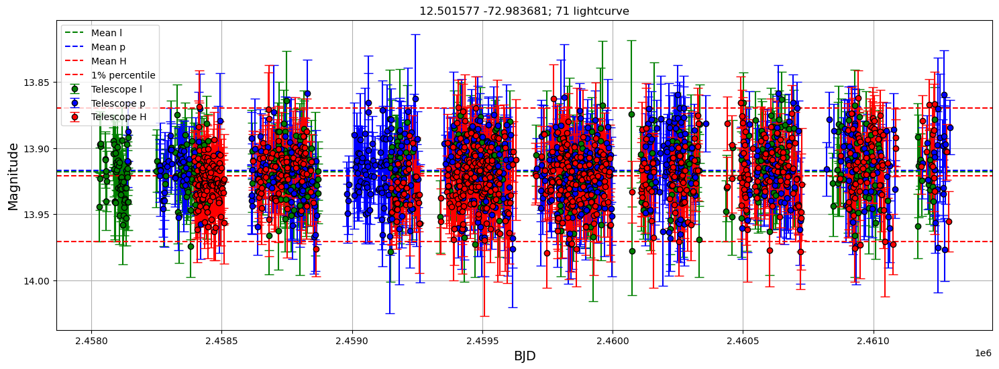

Best frequency: 0.003014 1/day, Best period: 331.76 days, Max power: 0.011, False alarm probability: 2.187e-01
False alarm level for 1.0%: 1.430e-02
Grid sampled at 17978 points


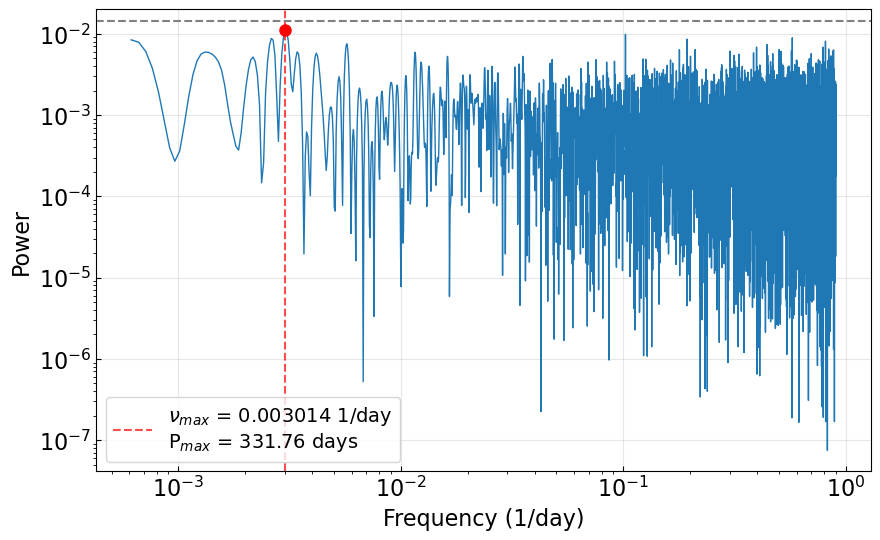

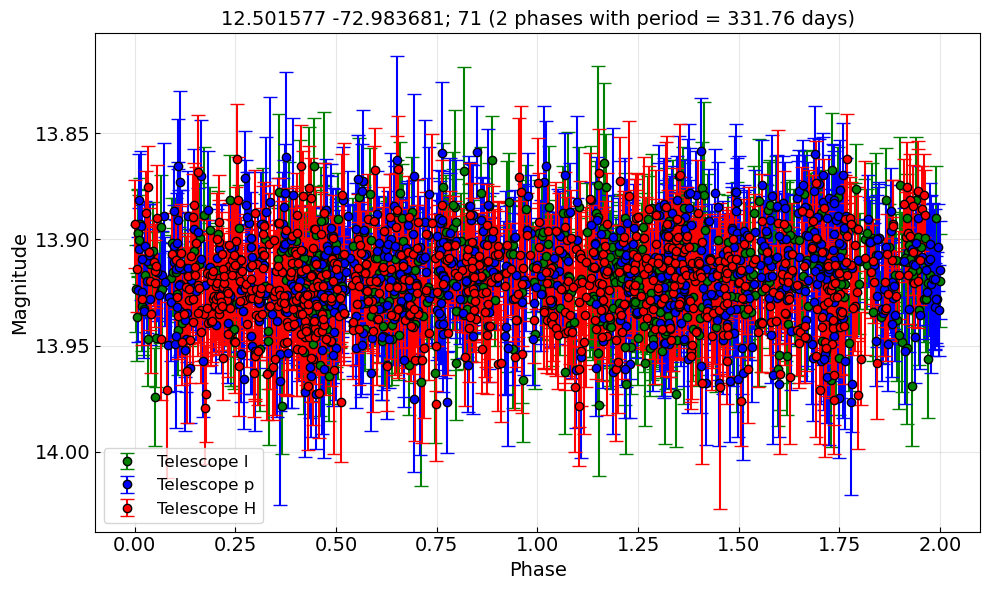

Average scatter (amplitude) per 10 point phase bin: 0.561 mJy


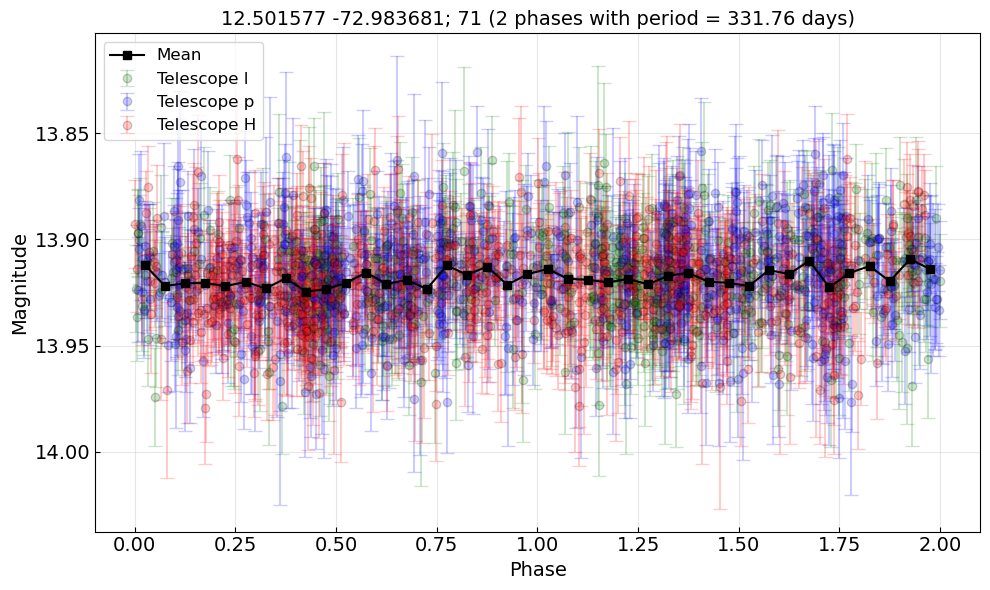

Average scatter (amplitude) per 10 point phase bin: 0.561 mJy
[0.00131318 0.00216369 0.0030142  ... 0.89794877 0.89844907 0.89929958]
Amplitude metrics:
	Lower 5% percentile: -0.33 mJy, 13.88 mags
	Upper 5% percentile: 0.32 mJy, 13.96 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 0.65 mJy, 0.07 mags
Amplitude metrics:
	Lower 1% percentile: -0.47 mJy, 13.87 mags
	Upper 1% percentile: 0.45 mJy, 13.97 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 0.92 mJy, 0.10 mags
	Largest amplitude of variability (g-band: True): 1.10 mJy, 0.12 mags
	Average amplitude across all periods: 1.039 mJy
	Standard deviation of amplitudes: 0.044 mJy
	Average amplitude (1.039 mJy) is greater than 5 sigma (0.044 mJy). This indicates consistent variability across periods.
Star index: 74, Best period: 331.8937957031928


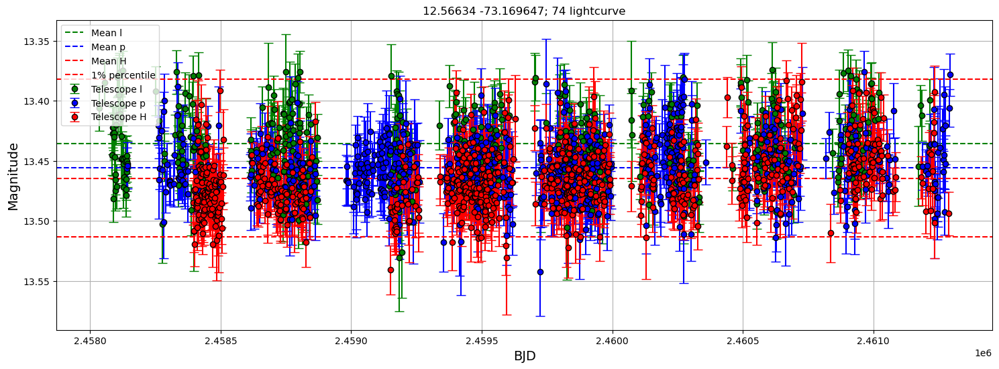

Best frequency: 0.003013 1/day, Best period: 331.89 days, Max power: 0.020, False alarm probability: 3.287e-05
False alarm level for 1.0%: 1.455e-02
Grid sampled at 17618 points


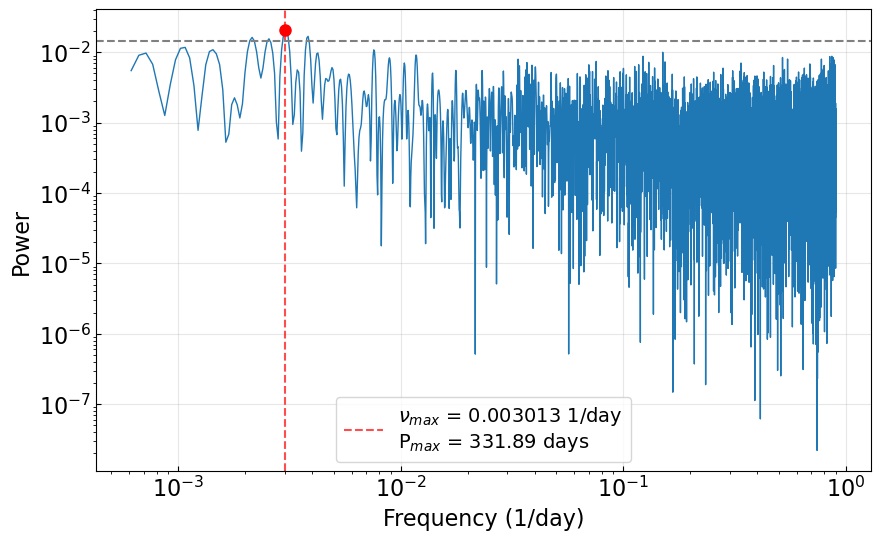

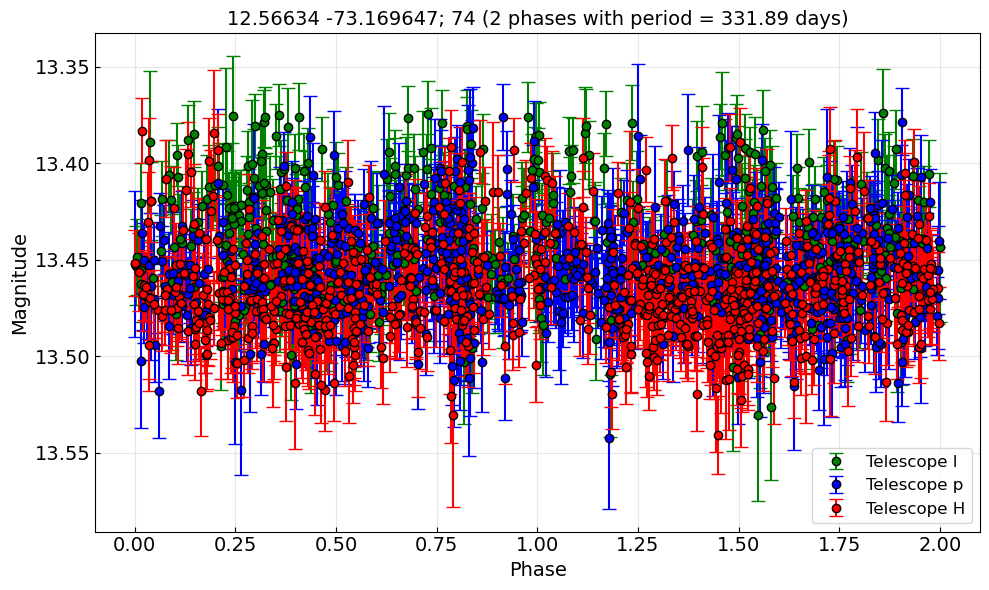

Average scatter (amplitude) per 10 point phase bin: 1.106 mJy


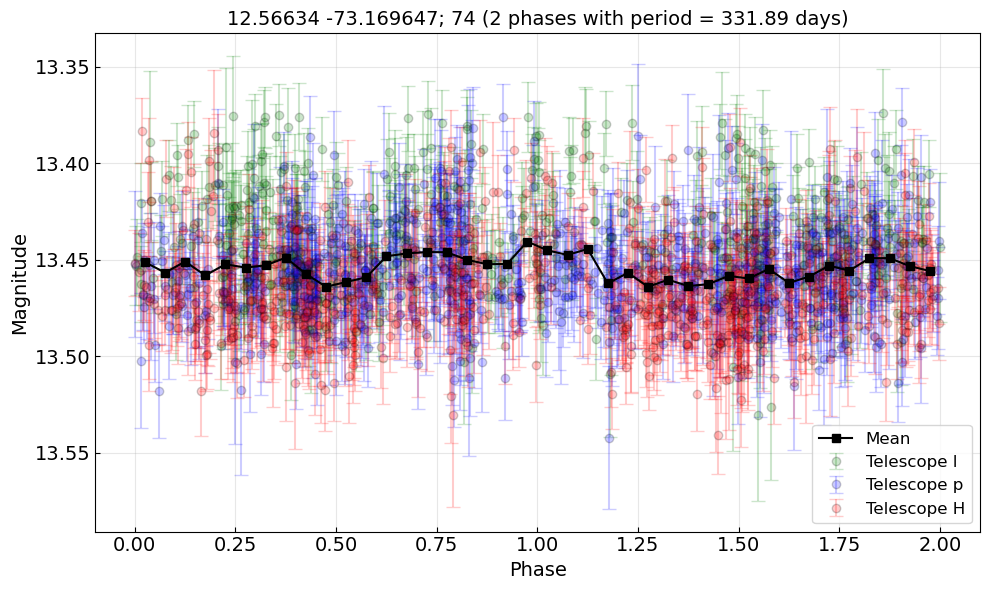

Average scatter (amplitude) per 10 point phase bin: 1.106 mJy
[0.00214512 0.00301301 0.00382985]
Amplitude metrics:
	Lower 5% percentile: -0.52 mJy, 13.40 mags
	Upper 5% percentile: 0.77 mJy, 13.50 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 1.29 mJy, 0.09 mags
Amplitude metrics:
	Lower 1% percentile: -0.76 mJy, 13.38 mags
	Upper 1% percentile: 1.08 mJy, 13.51 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 1.84 mJy, 0.13 mags
	Largest amplitude of variability (g-band: True): 2.33 mJy, 0.17 mags
	Average amplitude across all periods: 2.015 mJy
	Standard deviation of amplitudes: 0.131 mJy
	Average amplitude (2.015 mJy) is greater than 5 sigma (0.131 mJy). This indicates consistent variability across periods.
Star index: 75, Best period: 331.76288773970174


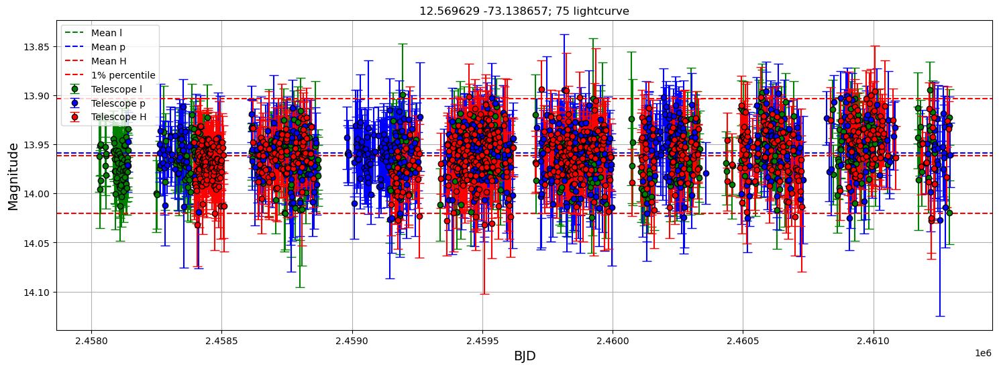

Best frequency: 0.003014 1/day, Best period: 331.76 days, Max power: 0.020, False alarm probability: 4.202e-05
False alarm level for 1.0%: 1.430e-02
Grid sampled at 17978 points


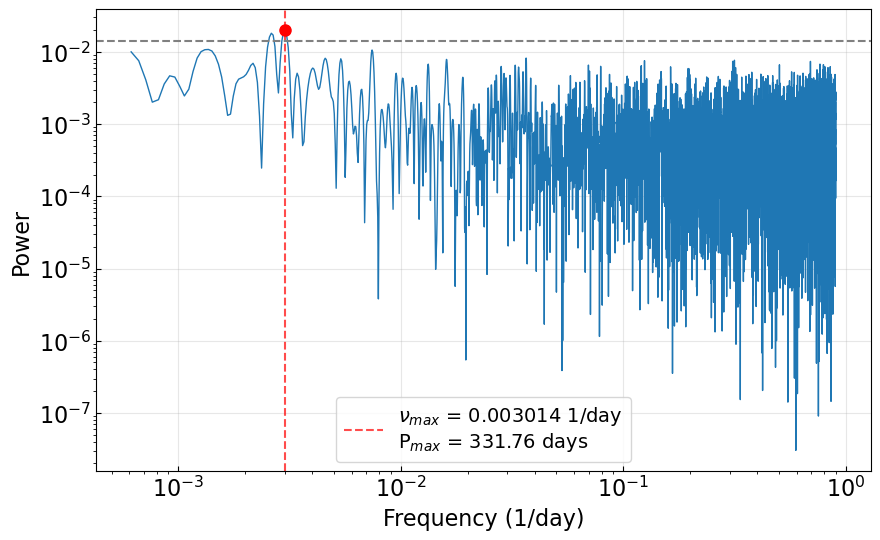

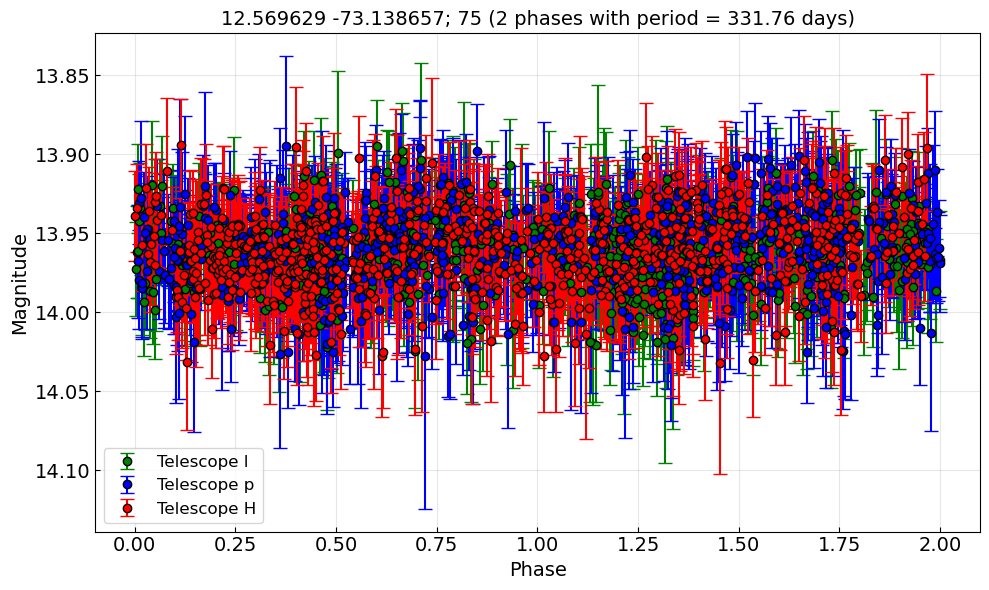

Average scatter (amplitude) per 10 point phase bin: 0.613 mJy


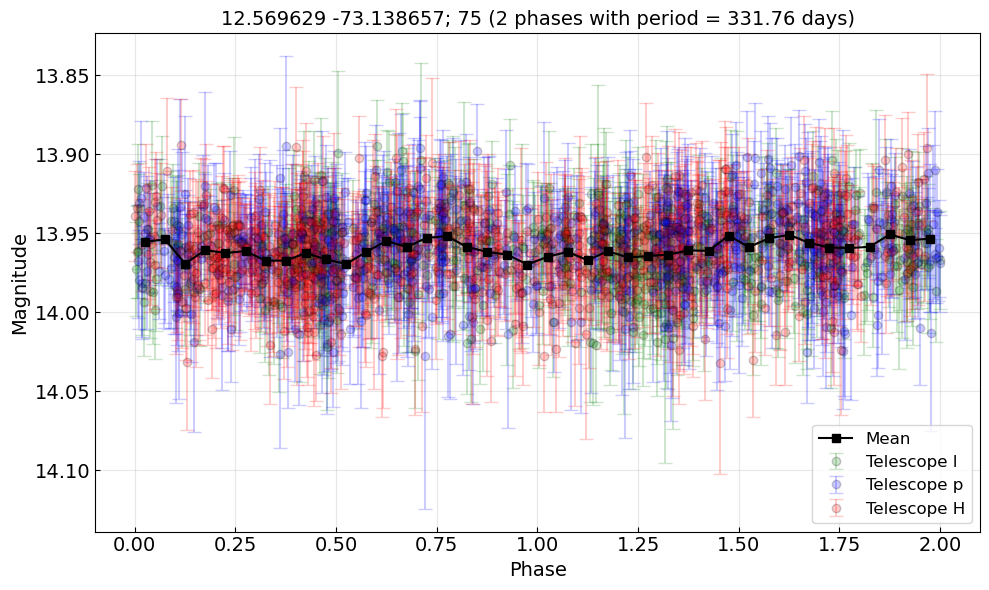

Average scatter (amplitude) per 10 point phase bin: 0.613 mJy
[0.0030142]
Amplitude metrics:
	Lower 5% percentile: -0.37 mJy, 13.92 mags
	Upper 5% percentile: 0.33 mJy, 14.00 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 0.70 mJy, 0.08 mags
Amplitude metrics:
	Lower 1% percentile: -0.52 mJy, 13.90 mags
	Upper 1% percentile: 0.50 mJy, 14.02 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 1.02 mJy, 0.12 mags
	Largest amplitude of variability (g-band: True): 1.20 mJy, 0.14 mags
	Average amplitude across all periods: 1.075 mJy
	Standard deviation of amplitudes: 0.076 mJy
	Average amplitude (1.075 mJy) is greater than 5 sigma (0.076 mJy). This indicates consistent variability across periods.
Star index: 87, Best period: 330.3856439437335


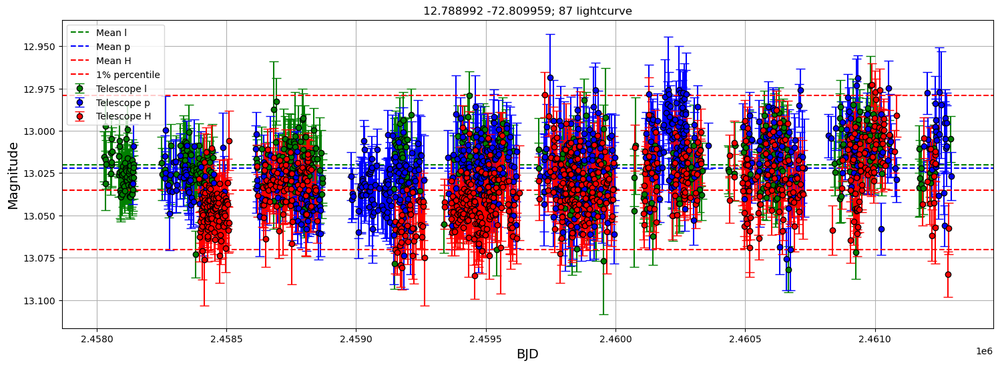

Best frequency: 0.003027 1/day, Best period: 330.39 days, Max power: 0.056, False alarm probability: 2.277e-21
False alarm level for 1.0%: 1.410e-02
Grid sampled at 18257 points


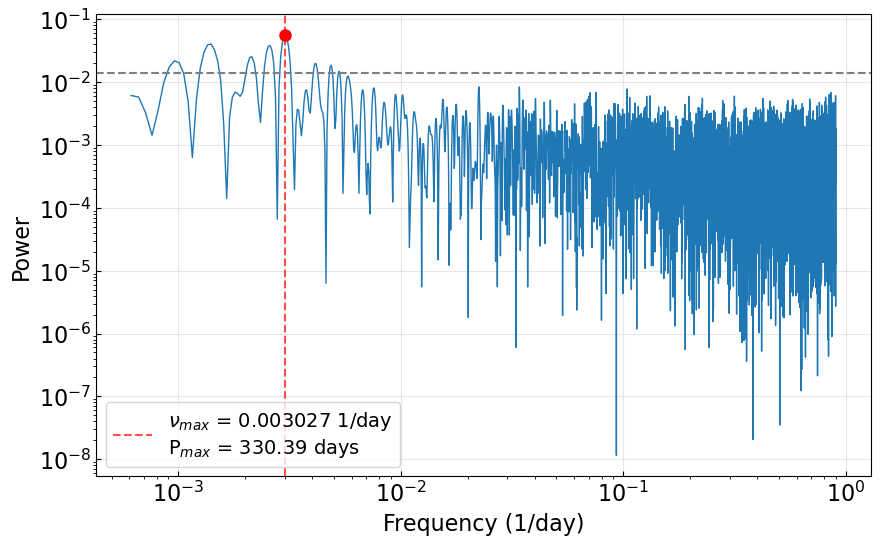

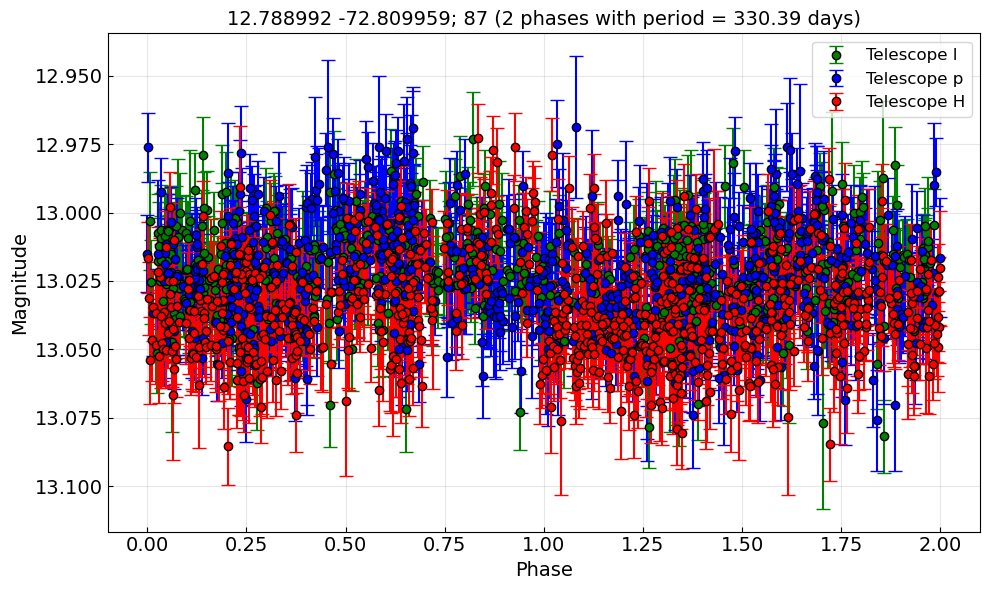

Average scatter (amplitude) per 10 point phase bin: 1.111 mJy


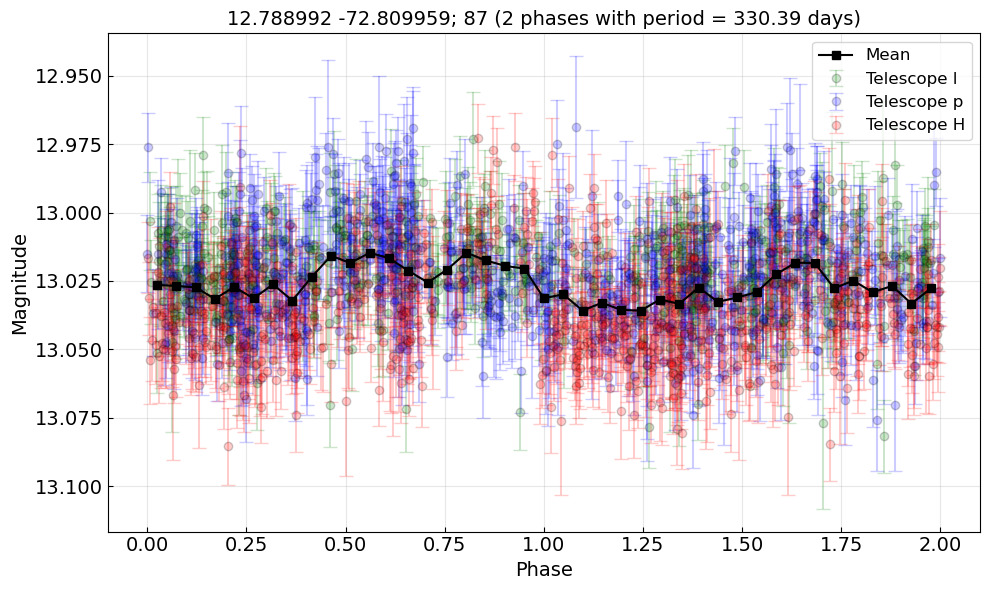

Average scatter (amplitude) per 10 point phase bin: 1.111 mJy
[0.00140101 0.00213999 0.00302677 0.0041106  0.00484958]
Amplitude metrics:
	Lower 5% percentile: -0.64 mJy, 13.00 mags
	Upper 5% percentile: 0.64 mJy, 13.06 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 1.28 mJy, 0.06 mags
Amplitude metrics:
	Lower 1% percentile: -0.89 mJy, 12.98 mags
	Upper 1% percentile: 0.99 mJy, 13.07 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 1.88 mJy, 0.09 mags
	Largest amplitude of variability (g-band: True): 2.41 mJy, 0.12 mags
	Average amplitude across all periods: 1.903 mJy
	Standard deviation of amplitudes: 0.250 mJy
	Average amplitude (1.903 mJy) is greater than 5 sigma (0.250 mJy). This indicates consistent variability across periods.
Star index: 88, Best period: 329.085318469968


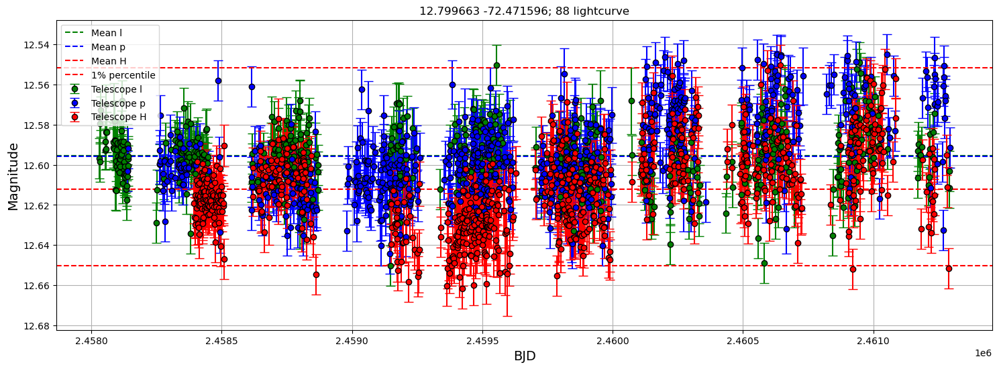

Best frequency: 0.003039 1/day, Best period: 329.09 days, Max power: 0.066, False alarm probability: 7.249e-26
False alarm level for 1.0%: 1.419e-02
Grid sampled at 18167 points


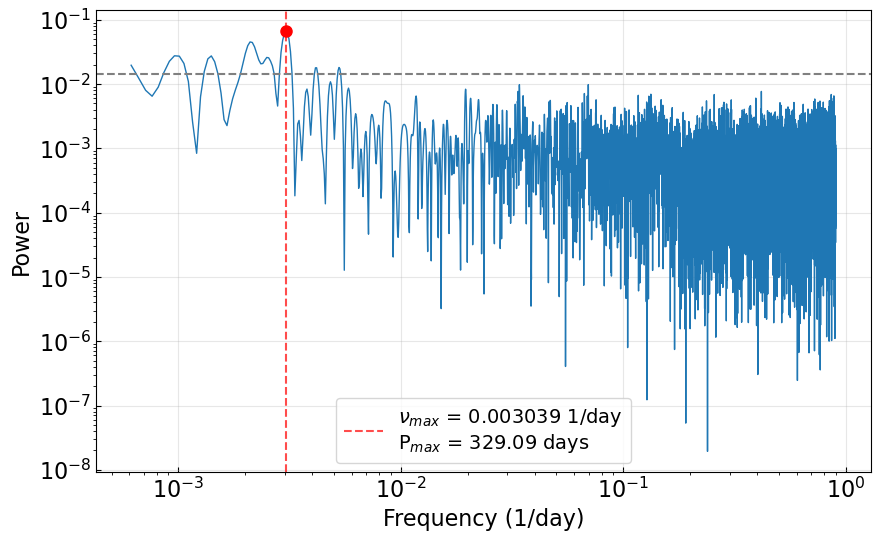

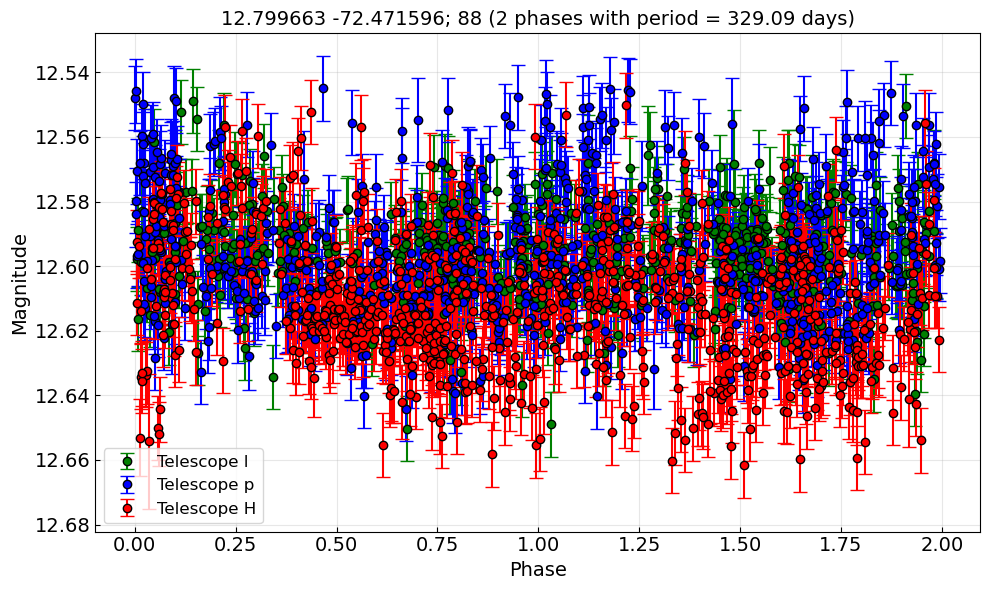

Average scatter (amplitude) per 10 point phase bin: 1.773 mJy


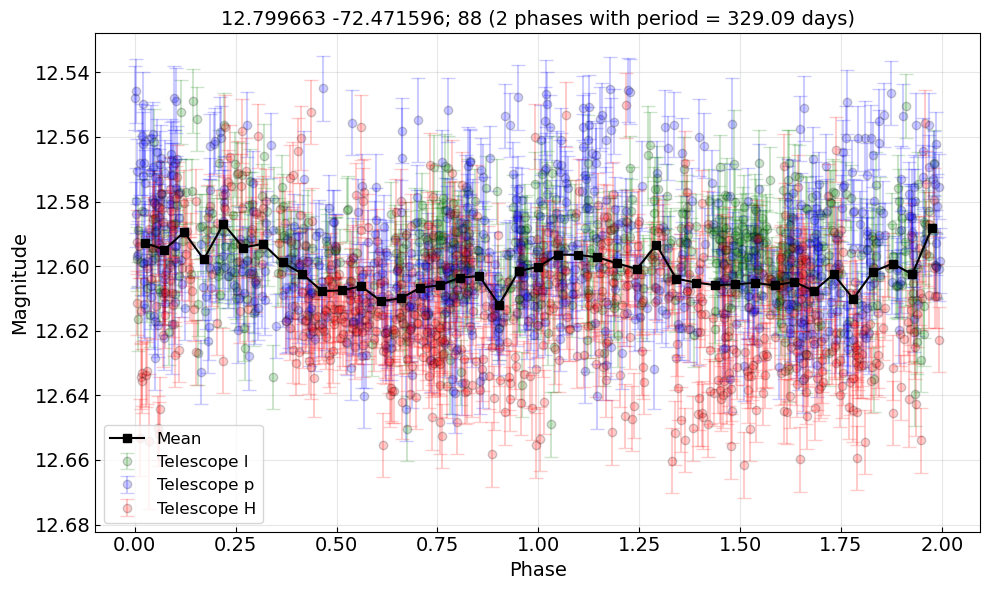

Average scatter (amplitude) per 10 point phase bin: 1.773 mJy
[0.00095933 0.00209805 0.00303873 0.00417744 0.00526665]
Amplitude metrics:
	Lower 5% percentile: -1.02 mJy, 12.57 mags
	Upper 5% percentile: 1.06 mJy, 12.64 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 2.08 mJy, 0.07 mags
Amplitude metrics:
	Lower 1% percentile: -1.45 mJy, 12.55 mags
	Upper 1% percentile: 1.55 mJy, 12.65 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 3.00 mJy, 0.10 mags
	Largest amplitude of variability (g-band: True): 3.55 mJy, 0.12 mags
	Average amplitude across all periods: 3.012 mJy
	Standard deviation of amplitudes: 0.224 mJy
	Average amplitude (3.012 mJy) is greater than 5 sigma (0.224 mJy). This indicates consistent variability across periods.
Star index: 101, Best period: 329.08531878154236


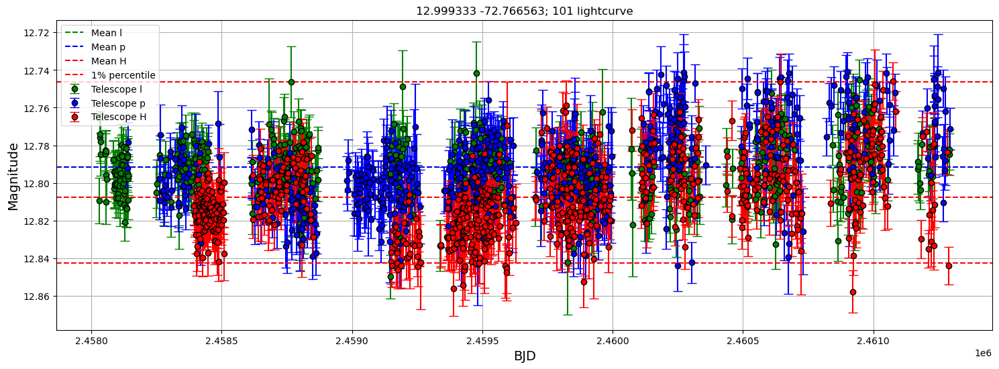

Best frequency: 0.003039 1/day, Best period: 329.09 days, Max power: 0.051, False alarm probability: 3.103e-19
False alarm level for 1.0%: 1.417e-02
Grid sampled at 18167 points


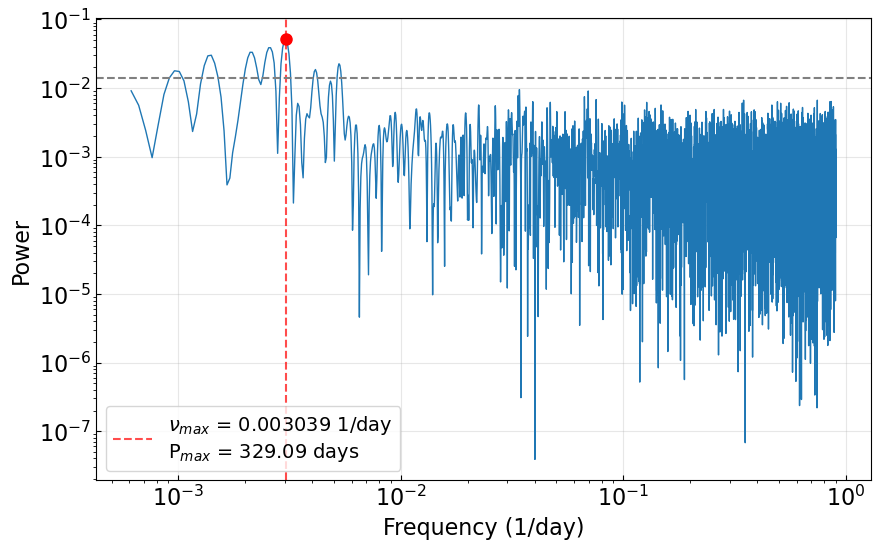

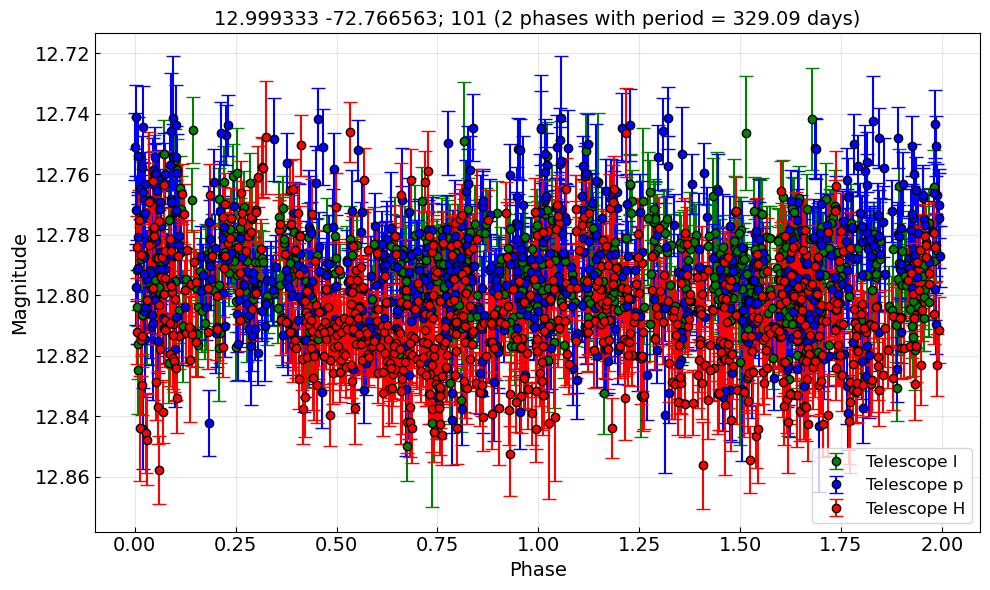

Average scatter (amplitude) per 10 point phase bin: 1.445 mJy


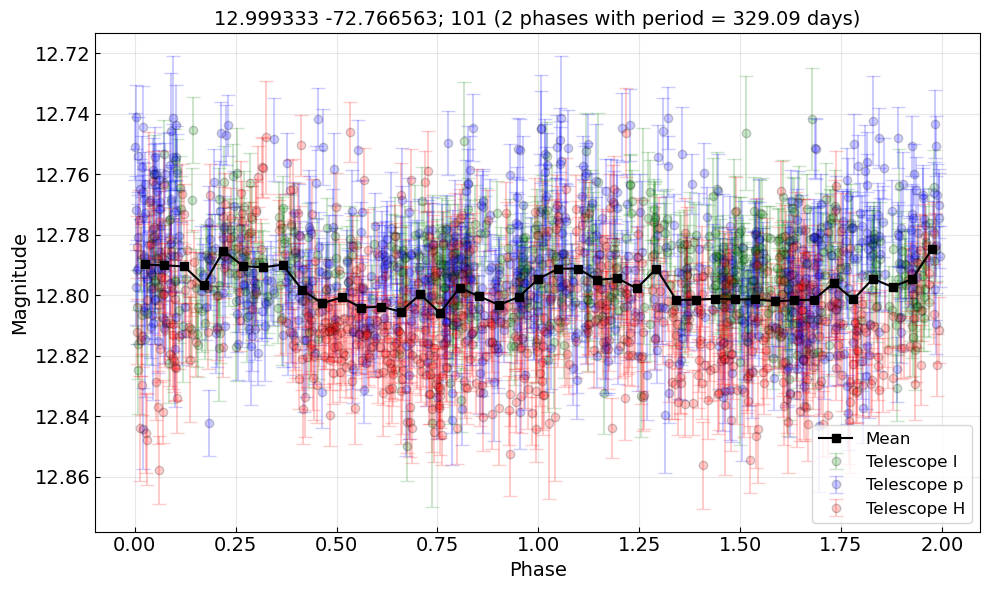

Average scatter (amplitude) per 10 point phase bin: 1.445 mJy
[0.00140492 0.00209805 0.00303873 0.00412793 0.00526665]
Amplitude metrics:
	Lower 5% percentile: -0.84 mJy, 12.76 mags
	Upper 5% percentile: 0.90 mJy, 12.83 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 1.74 mJy, 0.07 mags
Amplitude metrics:
	Lower 1% percentile: -1.12 mJy, 12.75 mags
	Upper 1% percentile: 1.34 mJy, 12.84 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 2.46 mJy, 0.10 mags
	Largest amplitude of variability (g-band: True): 2.97 mJy, 0.12 mags
	Average amplitude across all periods: 2.520 mJy
	Standard deviation of amplitudes: 0.308 mJy
	Average amplitude (2.520 mJy) is greater than 5 sigma (0.308 mJy). This indicates consistent variability across periods.


In [14]:
for star_idx in other_alias['star_idx'][:10]:
    print(f"Star index: {star_idx}, Best period: {other_alias.loc[star_idx, 'best_period']}")
    info(star_idx)